# [GSE205685](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE205685)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-09-28
> - Modified: 2024-09-28

# 1. Experimental Design

> Lysosomal Dynamics Orchestrate Neurogenesis. To determine the direct consequence of mTORC1 inactivation on translation efficiency, polysome profiling was performed for cortical neural progenitor cells that were dissected from mouse E13.5 brains and treated with Torin 1 for 2 h in vitro.
> - Zou, Wenzheng et al. Lysosomal dynamics regulate mammalian cortical neurogenesis. Developmental Cell, Volume 59, Issue 1, 64 - 78.e5.
> - total RNA-seq & Polysome-seq
> - Illumina HiSeq 3000, PE150
> - mm10

| Sample | Cell | Organism | Source | Strand | Genotype | Stage | Method | Fraction | Replicate |
| - | - | - | - | - | - | - | - | - | - |
| DMSO-rna | NPC | Mus musculus | Primary neural progenitor cells | E14Tg2A | WT | E13.5 | DMSO | Total RNA | rep1~3 |
| Torin1-rna | NPC | Mus musculus | Primary neural progenitor cells | E14Tg2A | WT | E13.5 | Torin 1 (2h) | Total RNA | rep1~3 |
| DMSO-polysome | NPC | Mus musculus | Primary neural progenitor cells | E14Tg2A | WT | E13.5 | DMSO | Polysome RNA | rep1~3 |
| Torin1-polysome | NPC | Mus musculus | Primary neural progenitor cells | E14Tg2A | WT | E13.5 | Torin 1 (2h) | Polysome RNA | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/polysomeseq_Mm_NPC_Torin1_GSE205685/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 22431    20

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("NPC"))) |>
    separate(
        col = sample, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("DMSO", "Torin1")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Fraction,Replicate
,<chr>,<fct>,<fct>,<fct>
DMSO_total_rep1,NPC,DMSO,Total,rep1
DMSO_total_rep2,NPC,DMSO,Total,rep2
DMSO_total_rep3,NPC,DMSO,Total,rep3
DMSO_polysome_rep1,NPC,DMSO,Polysome,rep1
DMSO_polysome_rep2,NPC,DMSO,Polysome,rep2
DMSO_polysome_rep3,NPC,DMSO,Polysome,rep3
Torin1_total_rep1,NPC,Torin1,Total,rep1
Torin1_total_rep2,NPC,Torin1,Total,rep2
Torin1_total_rep3,NPC,Torin1,Total,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

class: DESeqDataSet 
dim: 22431 12 
metadata(1): version
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(4): Cell Group Fraction Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("DMSO", "Torin1")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    select("sampleName", "fileName", "Cell", "Group", "Fraction", "Replicate") |>
    as.data.frame()

In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group * Fraction,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 22431 12 
metadata(1): version
assays(1): counts
rownames(22431): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118575.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(4): Cell Group Fraction Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("DMSO", "Torin1")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group * Fraction)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(4): Cell Group Fraction Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_", "", names),
        Group = factor(Group, levels = c("DMSO", "Torin1")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    select("names", "files", "Cell", "Group", "Fraction", "Replicate") |>
    as.data.frame()

In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-29 06:15:14

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene 

In [20]:
DESeqDataSet(gse, design = ~ Group * Fraction)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 12 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(5): names Cell Group Fraction Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("DMSO", "Torin1")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group * Fraction)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 12 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(4): Cell Group Fraction Replicate

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 22431 12 
metadata(0):
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(4): Cell Group Fraction Replicate

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

dds

class: DESeqDataSet 
dim: 22431 12 
metadata(1): version
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(12): DMSO_total_rep1 DMSO_total_rep2 ... Torin1_polysome_rep2
  Torin1_polysome_rep3
colData names(4): Cell Group Fraction Replicate

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 13365 
 Remove: 9066 
 Retention rate: 59.58 %


In [29]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 13356 
 Remove: 9075 
 Retention rate: 59.54 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [32]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [33]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [34]:
rld <- rlog(dds, blind = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


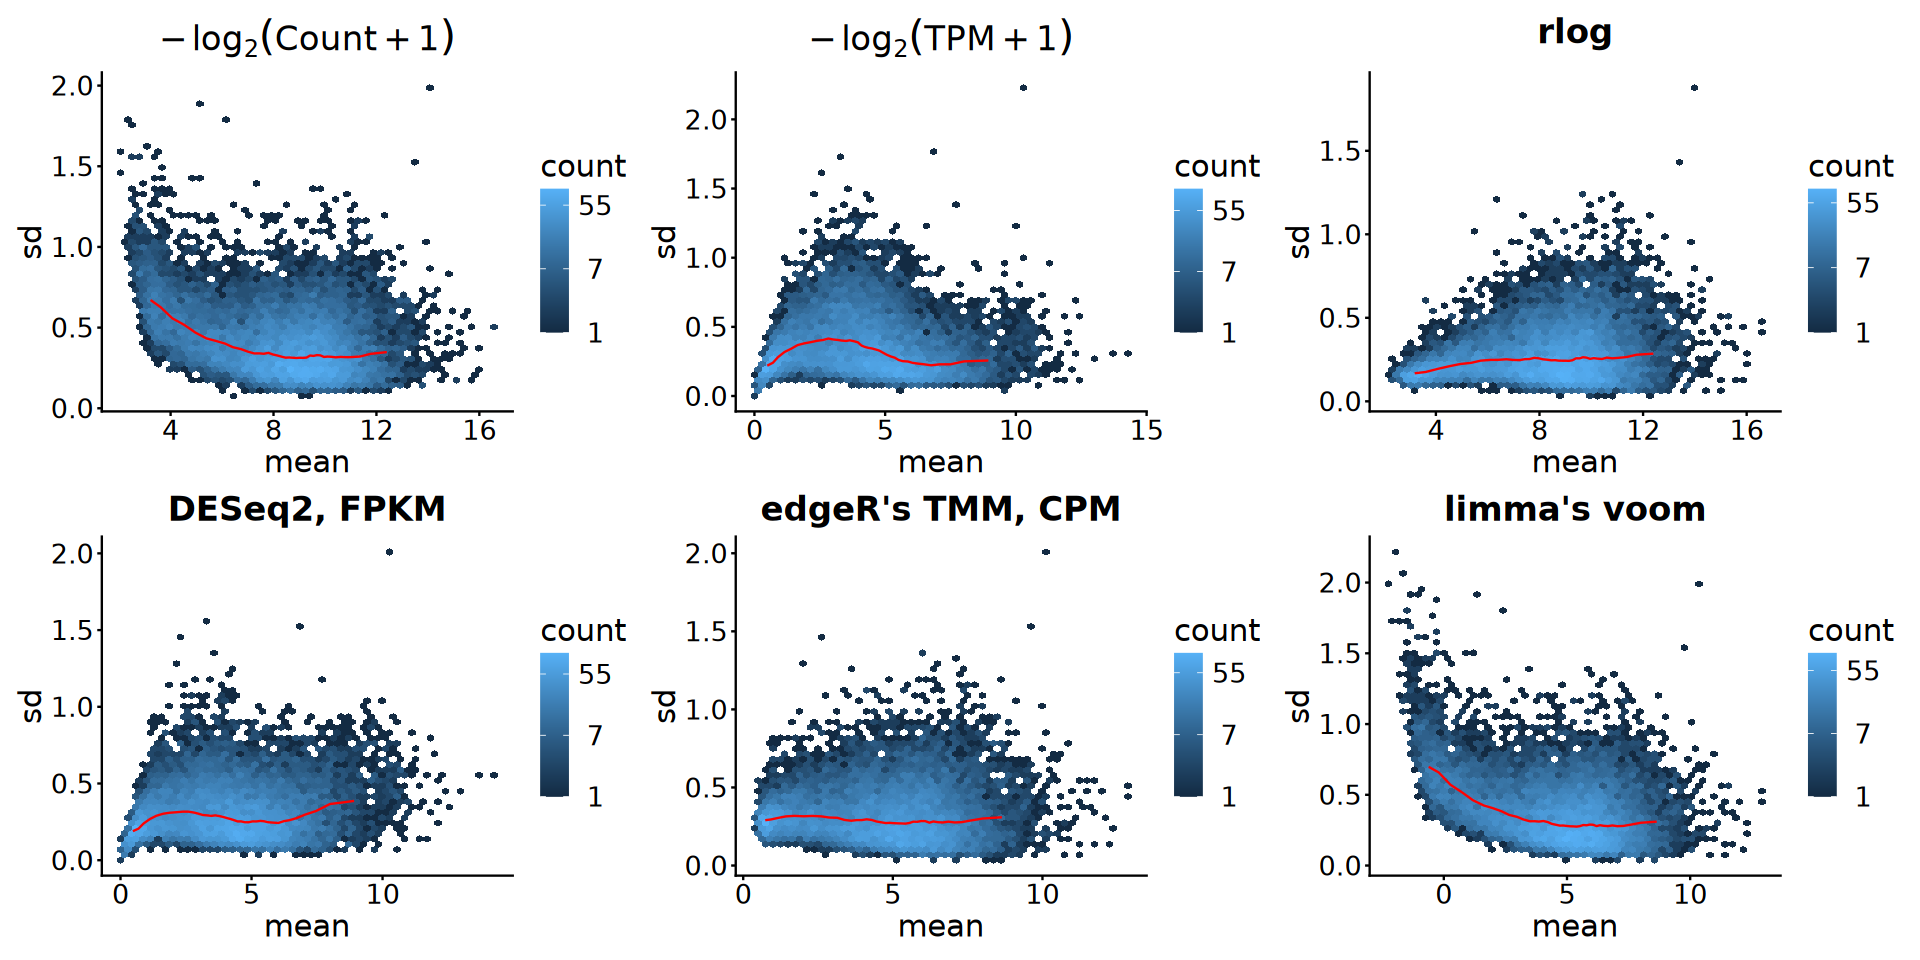

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Fraction, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

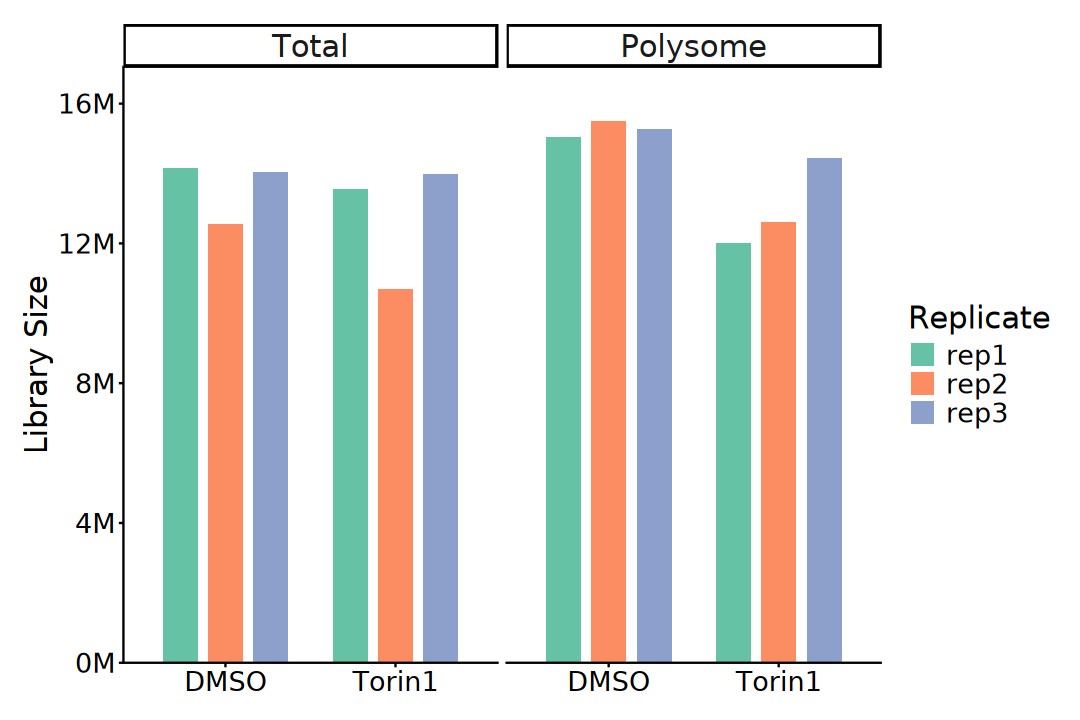

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(~ Fraction, nrow = 1) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [42]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [43]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [44]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [45]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Fraction", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [46]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [47]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [48]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

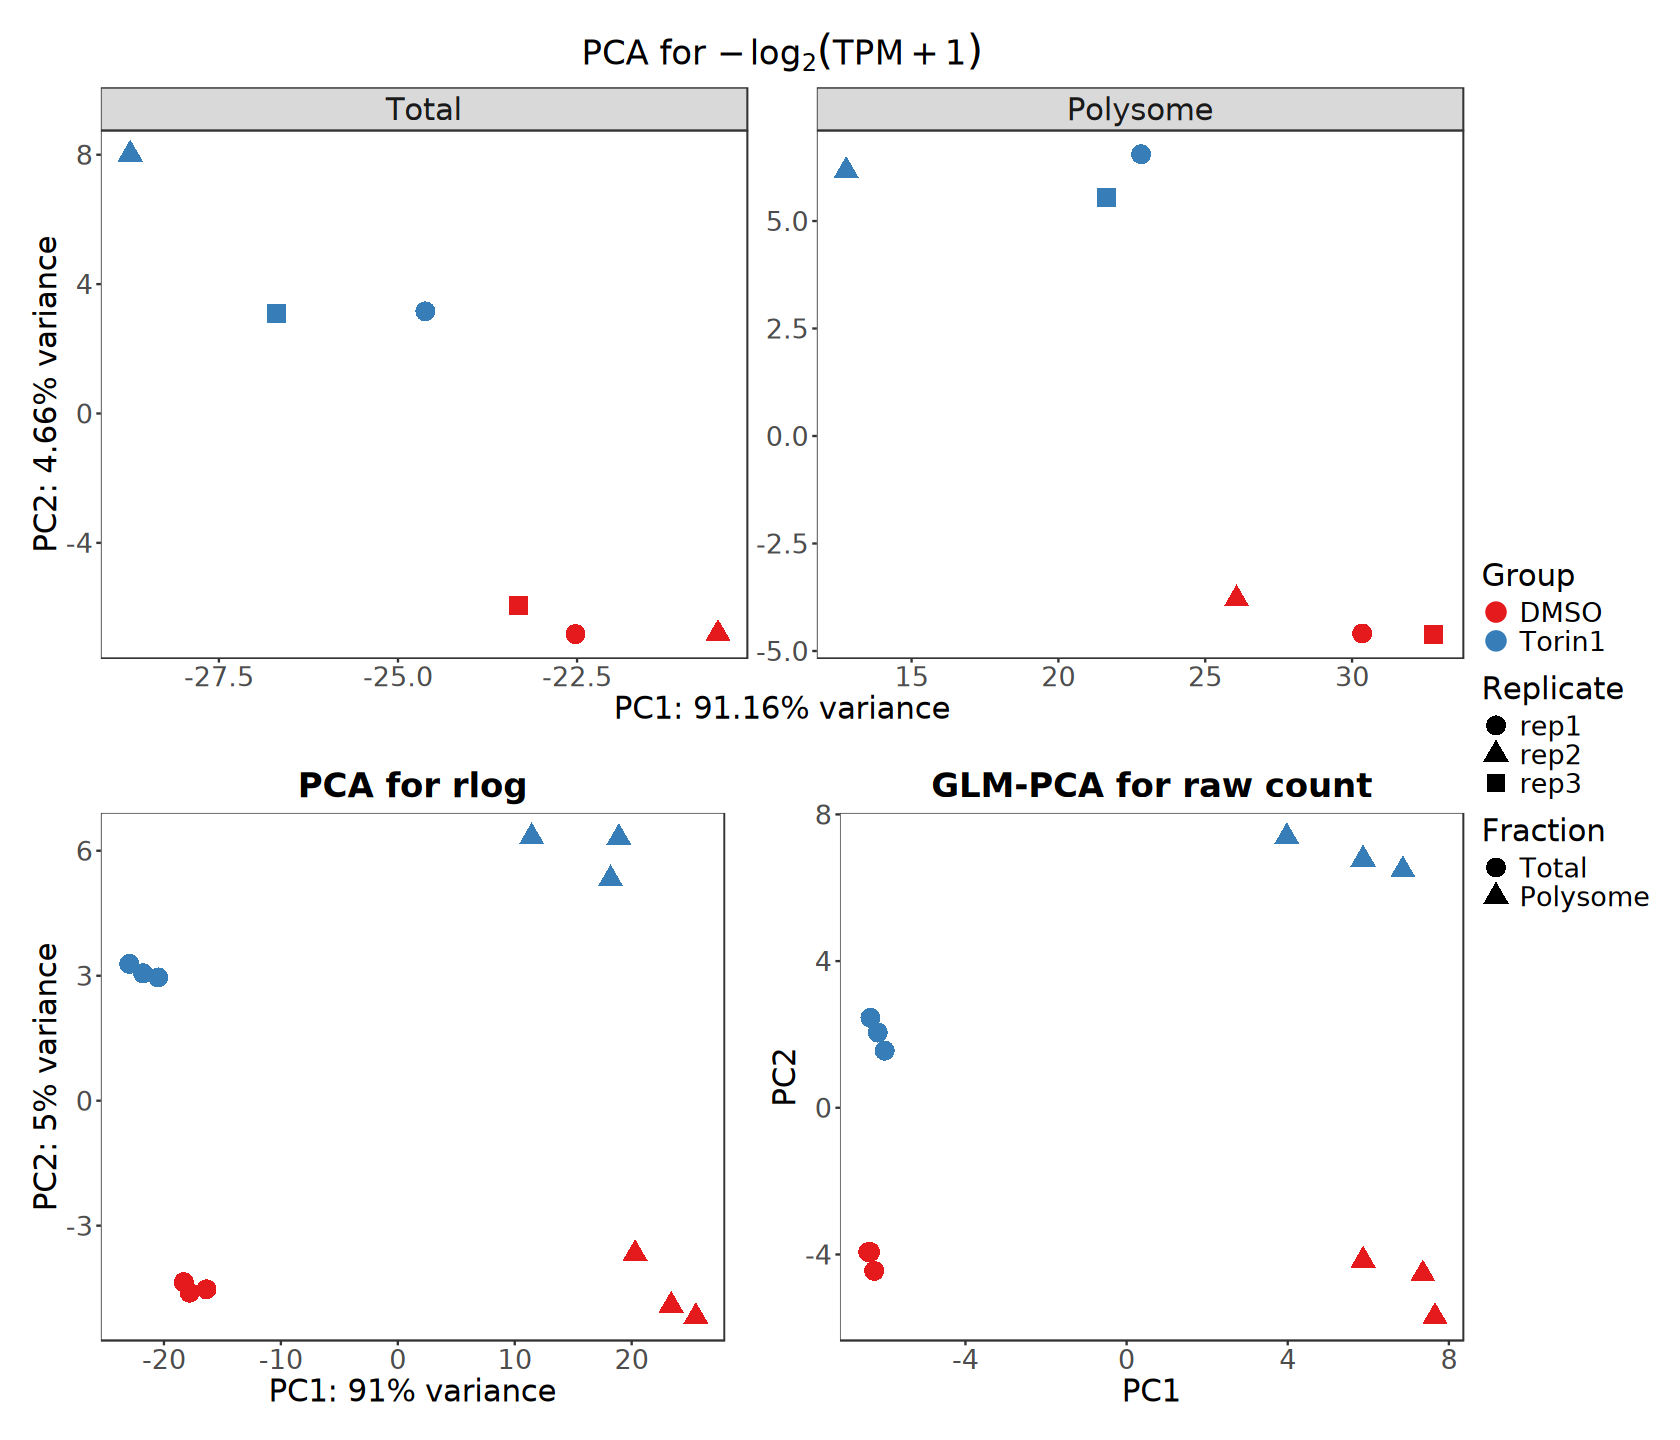

In [49]:
options(repr.plot.width = 14, repr.plot.height = 12)

p1 / (p2 + p3) + plot_layout(nrow = 2, guides = "collect")

## 3). MDS

> Multidimensional scaling

In [50]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

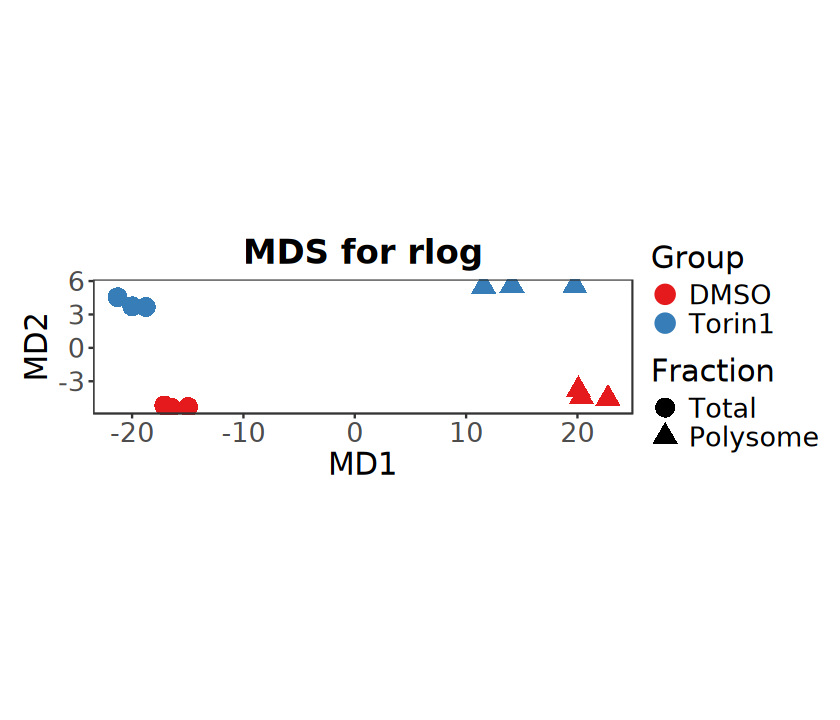

In [51]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 1) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [52]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

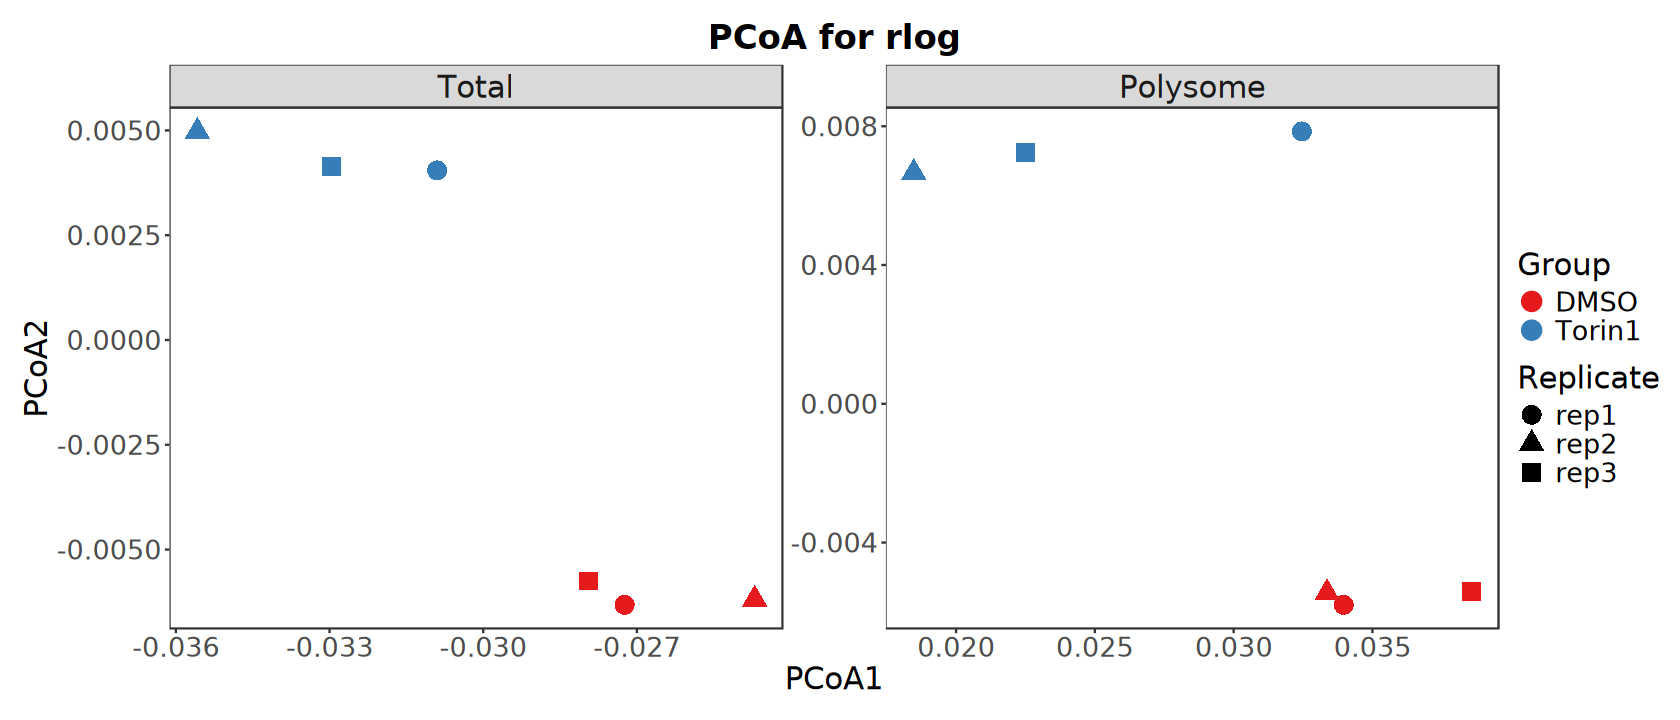

In [53]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [54]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [55]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Fraction = fraction_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [56]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

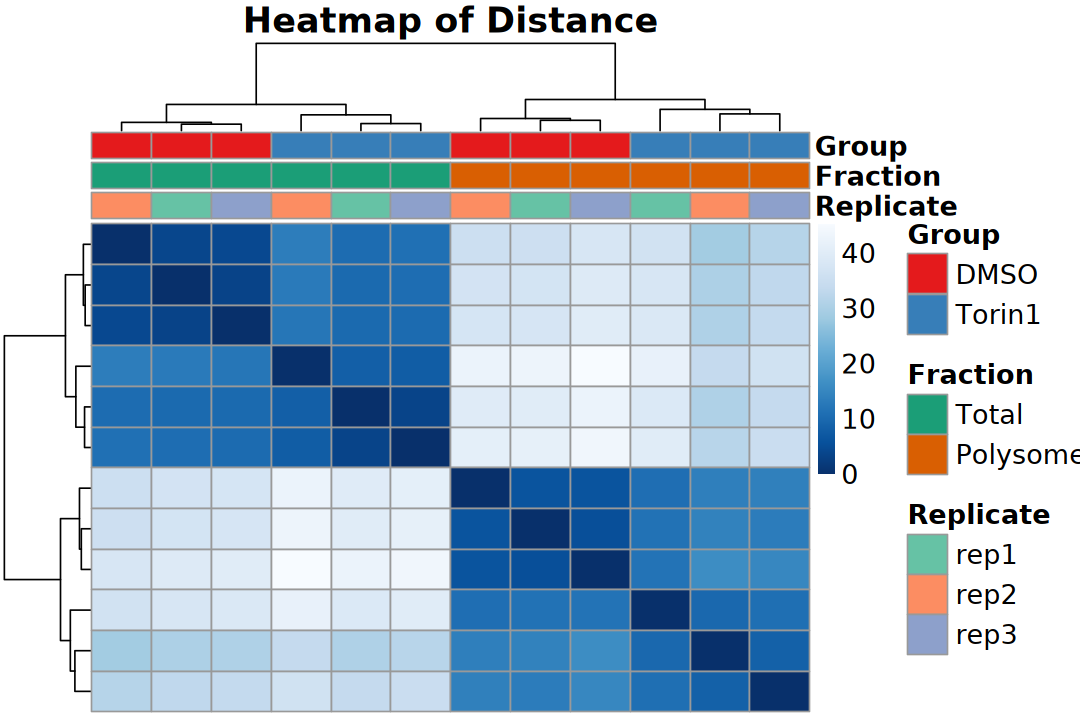

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [58]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

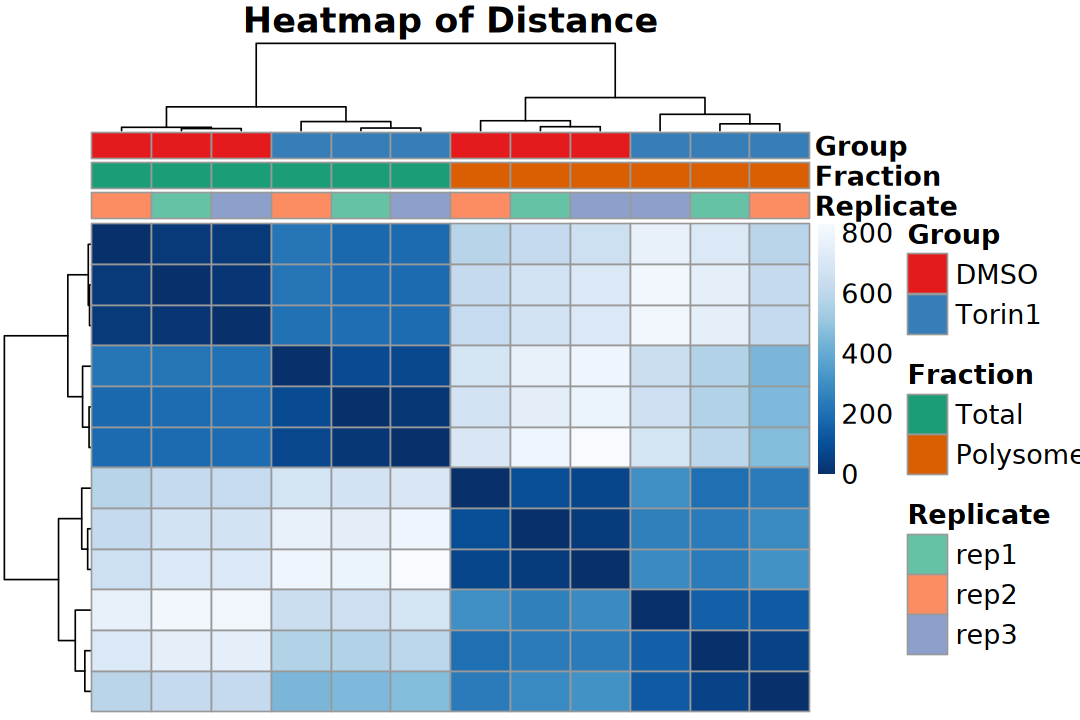

In [59]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [60]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

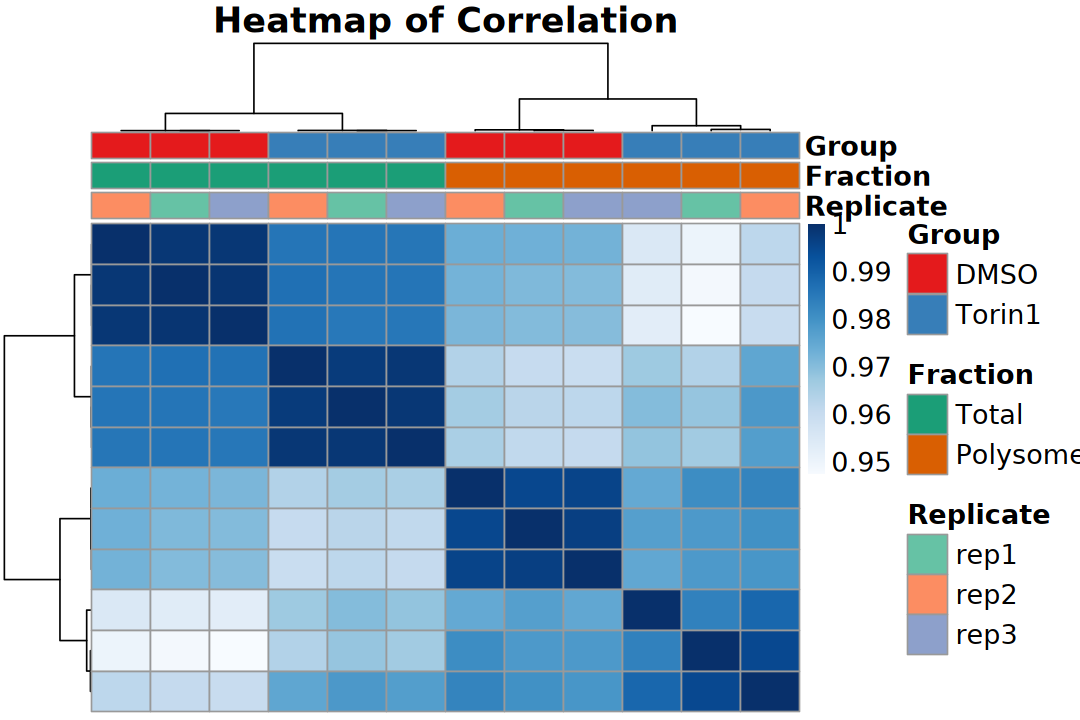

In [61]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

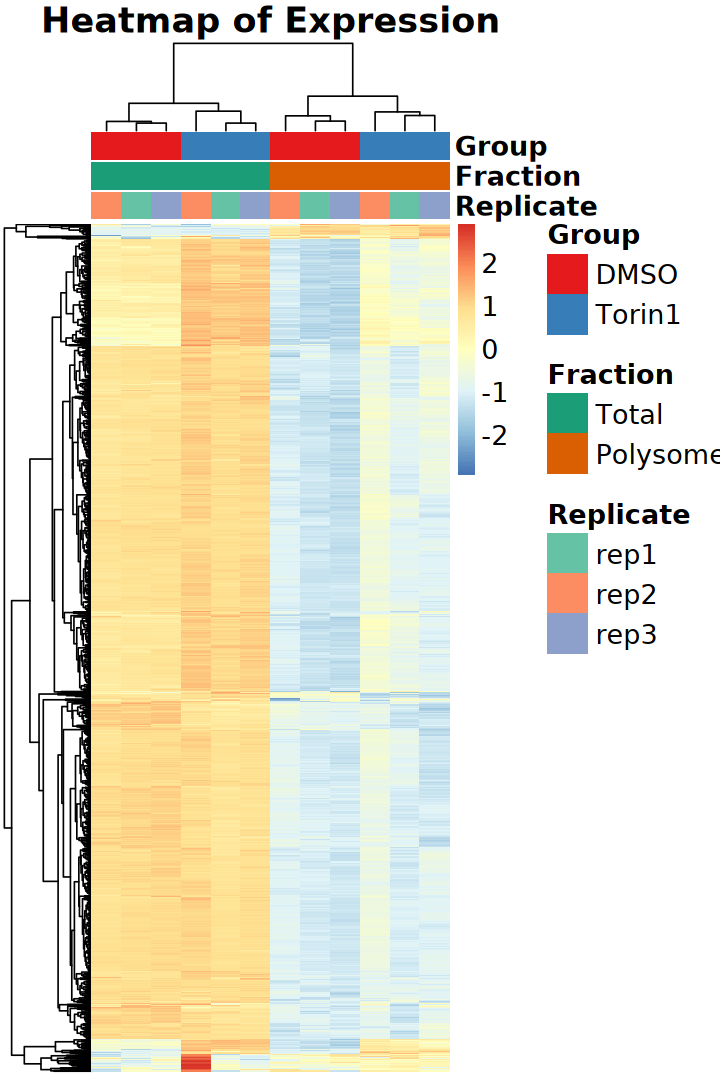

In [62]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. Translation Efficiency

<span style="font-size: 150%">

$$\log_2(\text{TE}) = \log_2\left(\frac{Polysome\ TPM}{Total\ TPM}\right)$$

$$\log_2(\text{TE}) = \log_2(\text{Polysome\ TPM}) - \log_2(\text{Total\ TPM})$$

</span>

In [63]:
calculate_log2_te <- function(
    exprmat, coldata, 
    group_col = "Group", group = c("Control", "Treat"), 
    fraction_col = "Fraction", fraction = c("Total", "Polysome"), 
    replicate_col = "Replicate", replicate = NULL, epsilon = 0) {
    
    # 1. Subset metadata for Total and Polysome fractions
    total_info <- coldata[coldata[[group_col]] == group & 
        coldata[[fraction_col]] == fraction[1], ]
    poly_info  <- coldata[coldata[[group_col]] == group & 
        coldata[[fraction_col]] == fraction[2], ]
    
    # 2. Handle biological replicates matching
    if (!is.null(replicate)) {
        if (is.numeric(replicate) && length(replicate) == 1) {
            sample_rep_vals <- as.character(coldata[[replicate_col]])
            replicate_ids <- if (any(grepl("rep", sample_rep_vals))) {
                paste0("rep", 1:replicate)
            } else {
                as.character(1:replicate)
            }
        } else {
            replicate_ids <- as.character(replicate)
        }
    
        total_info <- total_info[total_info[[replicate_col]] %in% replicate_ids, ]
        poly_info  <- poly_info[poly_info[[replicate_col]] %in% replicate_ids, ]

        # Ensure exact matching order of replicates between Total and Poly fractions
        poly_info  <- poly_info[match(
            total_info[[replicate_col]], poly_info[[replicate_col]]), ]
    
    }

    # 3. Extract expression matrices and compute log2 Translation Efficiency (TE)
    expr_total <- exprmat[, rownames(total_info), drop = FALSE]
    expr_poly  <- exprmat[, rownames(poly_info), drop = FALSE]
    
    log2_te <- log2(expr_poly + epsilon) - log2(expr_total + epsilon)

    # 4. Construct highly scalable column names automatically
    if (!is.null(replicate)) {
        colnames(log2_te) <- paste0(
            "log2TE_", group, "_", total_info[[replicate_col]])
    } else {
        if (nrow(total_info) == 1) {
            colnames(log2_te) <- paste0("log2TE_", group)
        } else {
            colnames(log2_te) <- paste0(
                "log2TE_", group, "_sample", 1:nrow(total_info))
        }
    }

    # 5. Convert all non-finite values (Inf, -Inf, NaN) to NA
    log2_te[!is.finite(log2_te)] <- NA
    
    return(as.matrix(log2_te))
}

In [64]:
te_ctrl  <- calculate_log2_te(
    tpm, colData(eSet), group = "DMSO", replicate = 3) |>
    rowMeans(na.rm = TRUE)
te_treat <- calculate_log2_te(
    tpm, colData(eSet), group = "Torin1", replicate = 3) |>
    rowMeans(na.rm = TRUE)

te_matrix <- cbind(te_ctrl, te_treat)
te_df <- te_matrix |> as.data.frame() |>
    rownames_to_column("gene_id") |>
    left_join(
        rowData(eSet) |> as.data.frame() |> 
            dplyr::select(-basepairs) |> 
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")
head(te_df)

,te_ctrl,te_treat,symbol,type
,<dbl>,<dbl>,<chr>,<chr>
ENSMUSG00000051951.5,-2.3319889,-1.7132332,Xkr4,protein_coding
ENSMUSG00000025902.13,-0.2993844,-0.5884883,Sox17,protein_coding
ENSMUSG00000033845.13,0.5781513,0.7045273,Mrpl15,protein_coding
ENSMUSG00000025903.14,-0.4022533,-0.3199362,Lypla1,protein_coding
ENSMUSG00000033813.15,-0.2390593,-0.1105790,Tcea1,protein_coding
ENSMUSG00000002459.17,-0.4061619,-0.3047164,Rgs20,protein_coding


In [65]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(te_df$te_ctrl) | is.infinite(te_df$te_treat)
has_nan_or_na <- is.na(te_df$te_ctrl) | is.na(te_df$te_treat)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- te_df[rows_with_abnormal, , drop = FALSE]

# 4. Output results to the console
if (nrow(abnormal_data) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(head(abnormal_data, 10))
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}

# Keep only rows that do not contain any abnormal values
# te_df <- te_df[!rows_with_abnormal, , drop = FALSE]

                       te_ctrl  te_treat  symbol           type
ENSMUSG00000028794.13 -1.21877       NaN A3galt2 protein_coding
ENSMUSG00000089901.1       NaN -3.493237  Gm8113 protein_coding


# 6. DTEGs

In [66]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

<span style="font-size: 150%">

$$\log_2\text{FC} = \log_2\left( \frac{\text{Polysome}_{\text{treat}}}{\text{Total}_{\text{treat}}} \right) - \log_2\left( \frac{\text{Polysome}_{\text{ctrl}}}{\text{Total}_{\text{ctrl}}} \right)$$

</span>

In [67]:
design(dds)

~Group * Fraction

In [68]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [69]:
resultsNames(dds)

[1] "Intercept"                    "Group_Torin1_vs_DMSO"        
[3] "Fraction_Polysome_vs_Total"   "GroupTorin1.FractionPolysome"

### a). Standard

In [70]:
# Examining whether treatment responses differ between the two cell types
res <- results(
    dds, name = "GroupTorin1.FractionPolysome",
    lfcThreshold = logfc_cutoff, alpha = p_cutoff)

summary(res)


out of 13365 with nonzero total read count
adjusted p-value < 0.05
LFC > 0.26 (up)    : 0, 0%
LFC < -0.26 (down) : 85, 0.64%
outliers [1]       : 2, 0.015%
low counts [2]     : 2849, 21%
(mean count < 80)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [71]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
    0    85 13280 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,198.26768,0.428941577,0.2266160,1.89281278,0.2331824,0.9999997,NS,Xkr4,protein_coding,1941
ENSMUSG00000025902.13,10.61804,-0.475225392,0.7020719,-0.67688990,0.5277406,NA,NS,Sox17,protein_coding,1369
ENSMUSG00000033845.13,1116.20824,-0.038525062,0.1685279,-0.22859747,0.9453766,0.9999997,NS,Mrpl15,protein_coding,1025
ENSMUSG00000025903.14,246.71051,-0.051251131,0.2438451,-0.21017904,0.9061649,0.9999997,NS,Lypla1,protein_coding,747
ENSMUSG00000033813.15,2630.12750,-0.006046729,0.2054587,-0.02943039,0.9896516,0.9999997,NS,Tcea1,protein_coding,999
ENSMUSG00000002459.17,411.45592,-0.071508558,0.1512223,-0.47287036,0.9108106,0.9999997,NS,Rgs20,protein_coding,1185


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [72]:
# Examining whether treatment responses differ between the two cell types
res_lfc <- lfcShrink(dds, coef = "GroupTorin1.FractionPolysome", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 13365 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 24, 0.18%
LFC < 0 (down)     : 129, 0.97%
outliers [1]       : 2, 0.015%
low counts [2]     : 0, 0%
(mean count < 5)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [73]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
   20   117 13228 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,198.26768,0.0308584032,0.07029959,0.05838277,0.9999818,NS,Xkr4,protein_coding,1941
ENSMUSG00000025902.13,10.61804,-0.0036430342,0.06130187,0.49847581,0.9999818,NS,Sox17,protein_coding,1369
ENSMUSG00000033845.13,1116.20824,-0.0048367835,0.05790732,0.81918179,0.9999818,NS,Mrpl15,protein_coding,1025
ENSMUSG00000025903.14,246.71051,-0.0030806621,0.05962323,0.83352794,0.9999818,NS,Lypla1,protein_coding,747
ENSMUSG00000033813.15,2630.12750,-0.0007539564,0.05881361,0.97652134,0.9999818,NS,Tcea1,protein_coding,999
ENSMUSG00000002459.17,411.45592,-0.0102611267,0.05789793,0.63630567,0.9999818,NS,Rgs20,protein_coding,1185


In [74]:
comparison_df <- deseq2_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_lfc = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    Raw = comparison_df$result_raw, 
    LFC_Shrink = comparison_df$result_lfc))


      LFC_Shrink
Raw       Up  Down    NS
  Up       0     0     0
  Down     0    85     0
  NS      20    32 13228


## 2). edgeR

> Trimmed Mean of M-values (TMM)

### a). Negative binomial GLM framework

In [75]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
colnames(design)

[1] "(Intercept)"                  "GroupTorin1"                 
[3] "FractionPolysome"             "GroupTorin1:FractionPolysome"

In [76]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [77]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = "GroupTorin1:FractionPolysome")

In [78]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
   22   134 13200 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000038900.17,Rpl12,protein_coding,616,-1.570373,8.845298,139.2896,3.806837e-32,5.084411e-28,Down
ENSMUSG00000000740.12,Rpl13,protein_coding,633,-1.205425,9.820417,123.7029,9.785268e-29,6.268301e-25,Down
ENSMUSG00000061983.7,Rps12,protein_coding,576,-1.778311,9.340656,122.9809,1.407974e-28,6.268301e-25,Down
ENSMUSG00000067274.10,Rplp0,protein_coding,951,-1.432343,10.241349,122.1845,2.103410e-28,7.023285e-25,Down
ENSMUSG00000030432.12,Rpl28,protein_coding,425,-1.335527,9.019072,112.8980,2.271604e-26,6.067910e-23,Down
ENSMUSG00000040952.16,Rps19,protein_coding,845,-1.942586,8.547770,103.3376,2.826427e-24,6.291626e-21,Down


### b). Quasi-likelihood pipeline (edgeR v3)

In [79]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)

In [80]:
dgel_nbglm <- estimateDisp(dgel, design)

In [81]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = "GroupTorin1:FractionPolysome")

In [82]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
    7   101 13248 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000038900.17,Rpl12,protein_coding,616,-1.570304,8.845298,164.7105,4.262855e-10,4.973210e-06,Down
ENSMUSG00000000740.12,Rpl13,protein_coding,633,-1.205414,9.820417,151.3380,8.127917e-10,4.973210e-06,Down
ENSMUSG00000067274.10,Rplp0,protein_coding,951,-1.432379,10.241349,141.6724,1.339385e-09,4.973210e-06,Down
ENSMUSG00000061983.7,Rps12,protein_coding,576,-1.778154,9.340656,139.1100,1.536914e-09,4.973210e-06,Down
ENSMUSG00000030432.12,Rpl28,protein_coding,425,-1.335526,9.019072,135.6077,1.861789e-09,4.973210e-06,Down
ENSMUSG00000025508.13,Rplp2,protein_coding,345,-1.323925,8.834386,116.0322,5.944946e-09,1.249772e-05,Down


In [83]:
comparison_df <- edger_glm_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, glm_lrt = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, glm_qlf = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    glm_lrt = comparison_df$glm_lrt, 
    glm_qlf = comparison_df$glm_qlf))


       glm_qlf
glm_lrt    Up  Down    NS
   Up       7     0    15
   Down     0   101    33
   NS       0     0 13200


## 3). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [84]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)

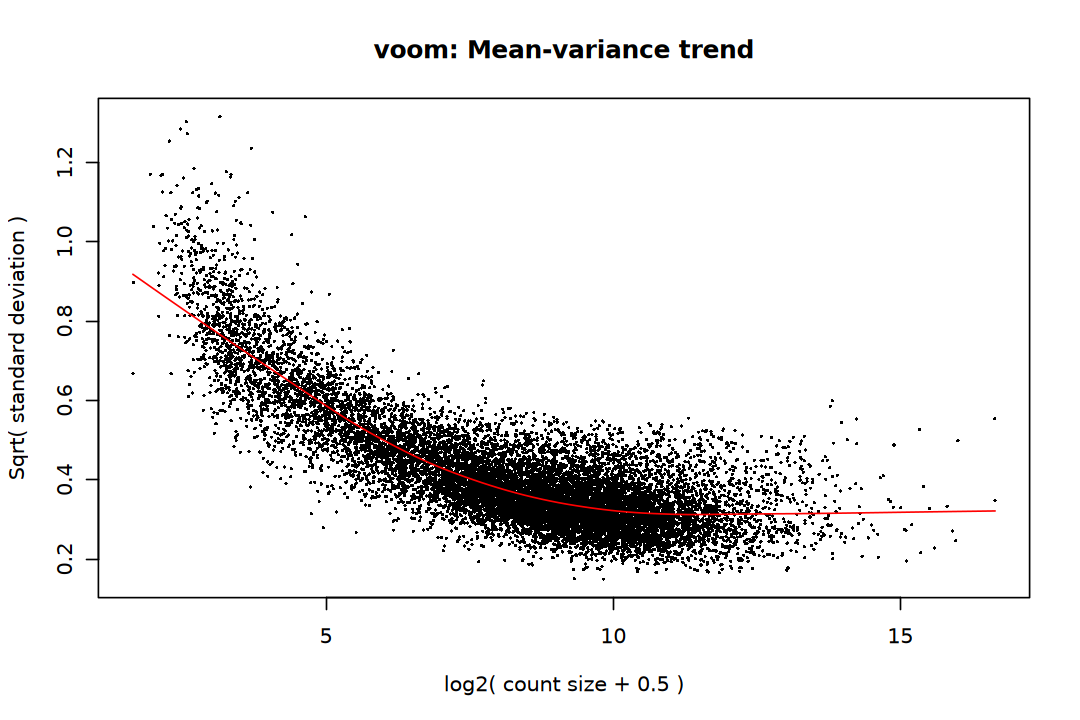

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)
norm_v <- voom(dgel, design, plot = TRUE)

In [86]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [87]:
limma_voom_result <- topTable(efit, coef = "GroupTorin1:FractionPolysome", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
    6   102 13248 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000038900.17,Rpl12,protein_coding,616,-1.573129,8.748277,-13.19706,2.380757e-10,2.166148e-06,13.60369,Down
ENSMUSG00000000740.12,Rpl13,protein_coding,633,-1.205001,9.768223,-12.93654,3.243708e-10,2.166148e-06,13.31830,Down
ENSMUSG00000067274.10,Rplp0,protein_coding,951,-1.434155,10.118740,-12.44717,5.881754e-10,2.618557e-06,12.78922,Down
ENSMUSG00000061983.7,Rps12,protein_coding,576,-1.779281,9.217954,-12.09620,9.120642e-10,2.861769e-06,12.41554,Down
ENSMUSG00000030432.12,Rpl28,protein_coding,425,-1.333825,8.951577,-11.96944,1.071342e-09,2.861769e-06,12.27497,Down
ENSMUSG00000022283.15,Pabpc1,protein_coding,1908,-1.032390,8.620372,-11.04378,3.622487e-09,6.367274e-06,11.17632,Down


In [88]:
comparison_df <- limma_voom_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, limma = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    limma = comparison_df$limma, 
    edger = comparison_df$edger))


      edger
limma     Up  Down    NS
  Up       5     0     1
  Down     0   100     2
  NS       2     1 13245


## DEGs Evaluation

In [89]:
add_label <- function(res, symbol_col = "symbol", type_col = "type") {
    res |> rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            valid = .data[[type_col]] == "protein_coding" & 
                result %in% c("Up", "Down"),
            label = dplyr::if_else(
                valid & cumsum(valid) <= 5, 
                .data[[symbol_col]], NA_character_)
        ) |>
        dplyr::ungroup() |>
        column_to_rownames("gene_id")
}

In [90]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [91]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [92]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

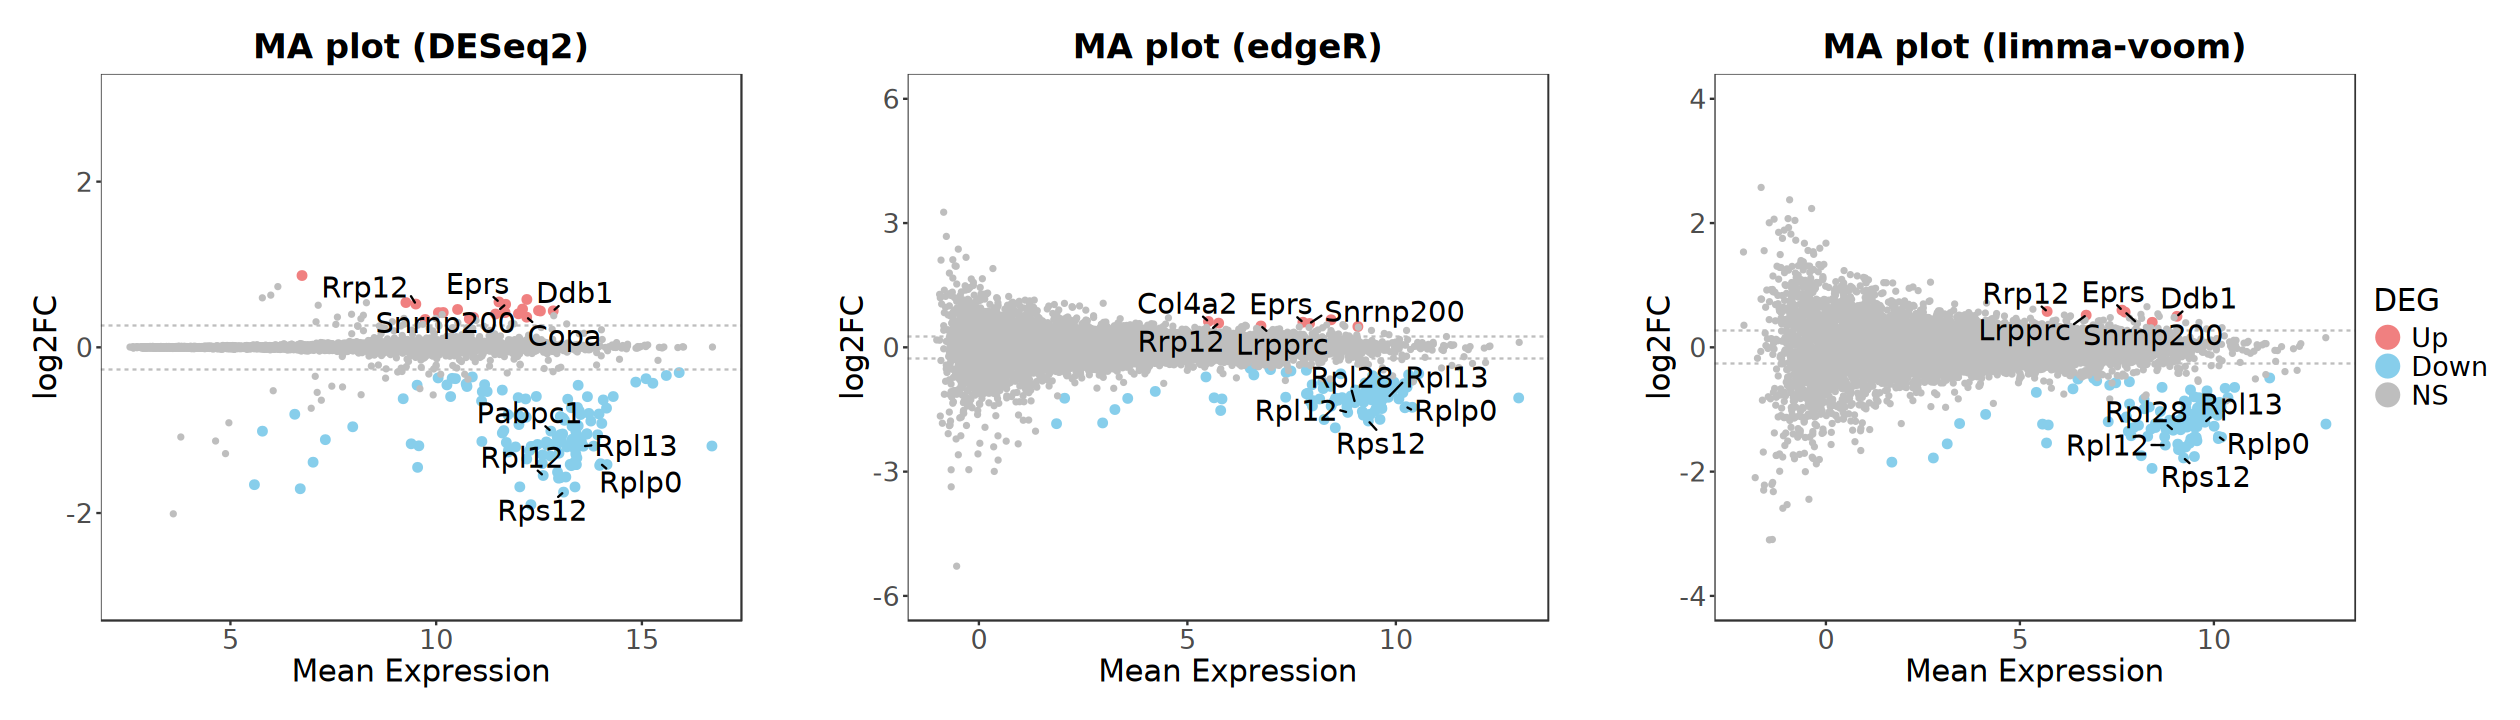

In [93]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [94]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [95]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

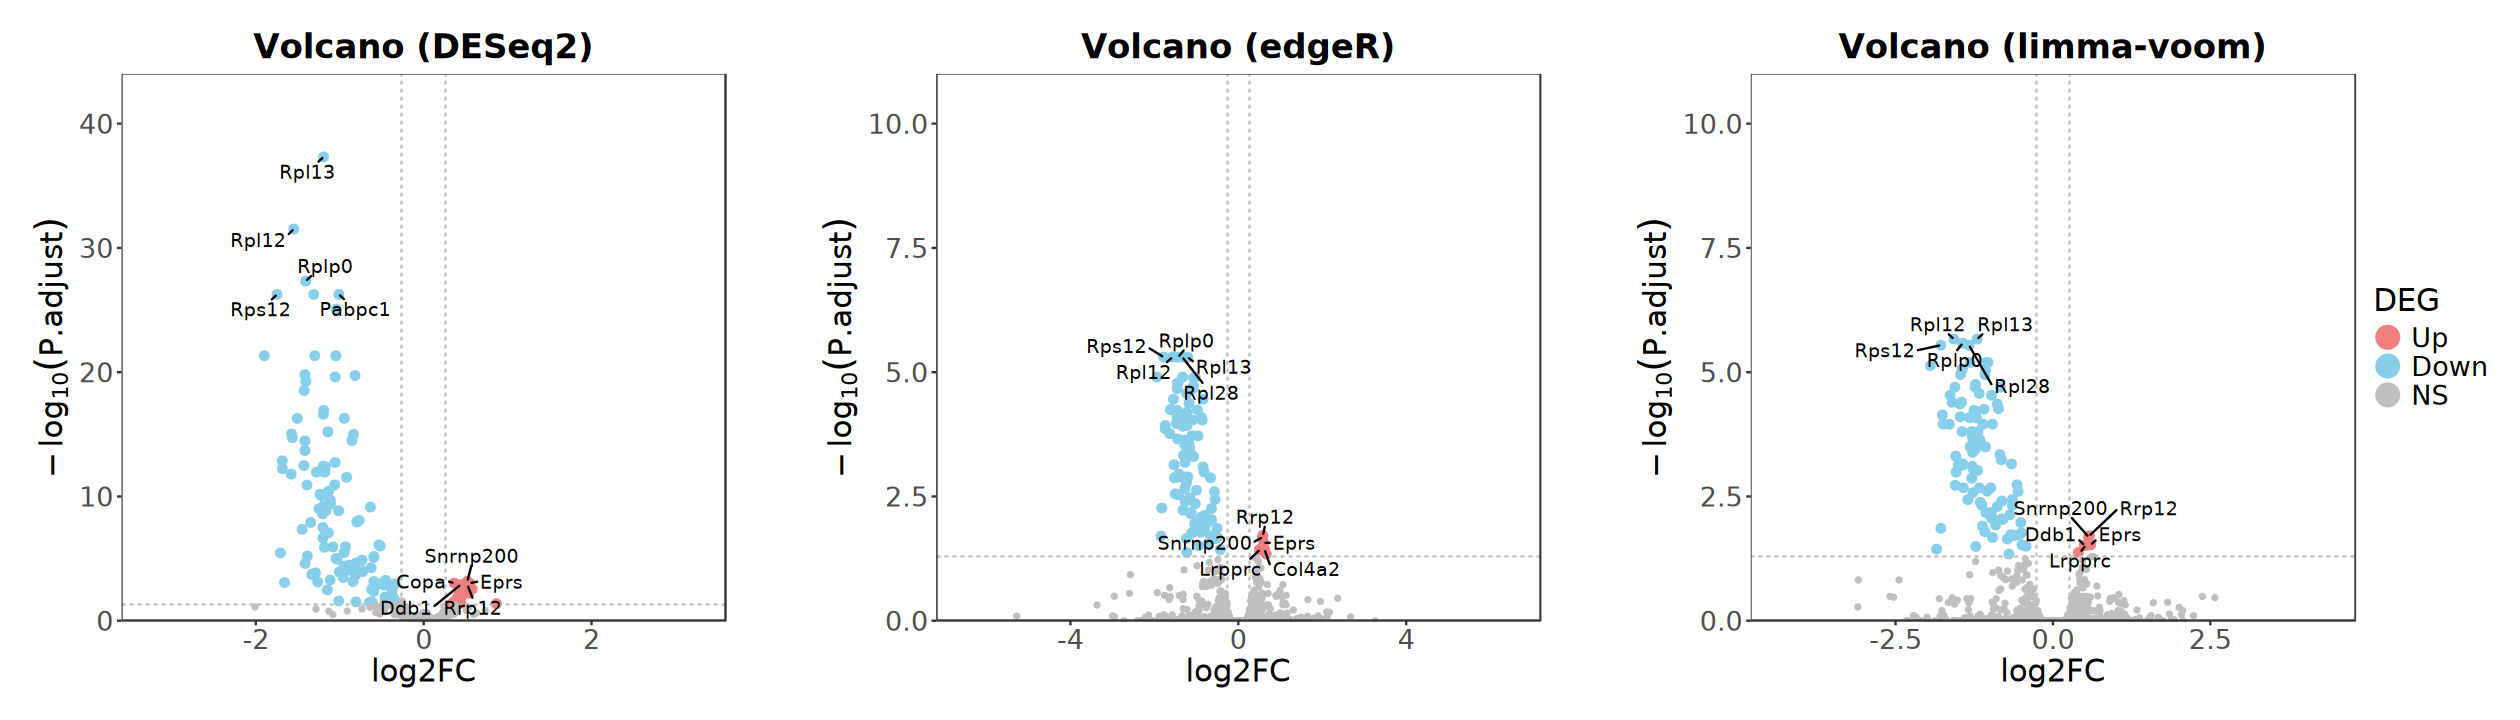

In [96]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [97]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [98]:
genes_up <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Up", "symbol"], 
    edgeR = edger_result[edger_result$result == "Up", "symbol"], 
    limma = limma_result[limma_result$result == "Up", "symbol"])
genes_up <- lapply(genes_up, unique)

In [99]:
genes_down <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Down", "symbol"], 
    edgeR = edger_result[edger_result$result == "Down", "symbol"], 
    limma = limma_result[limma_result$result == "Down", "symbol"])
genes_down <- lapply(genes_down, unique)

In [100]:
p1 <- ggVennDiagram(genes_up, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(genes_down, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

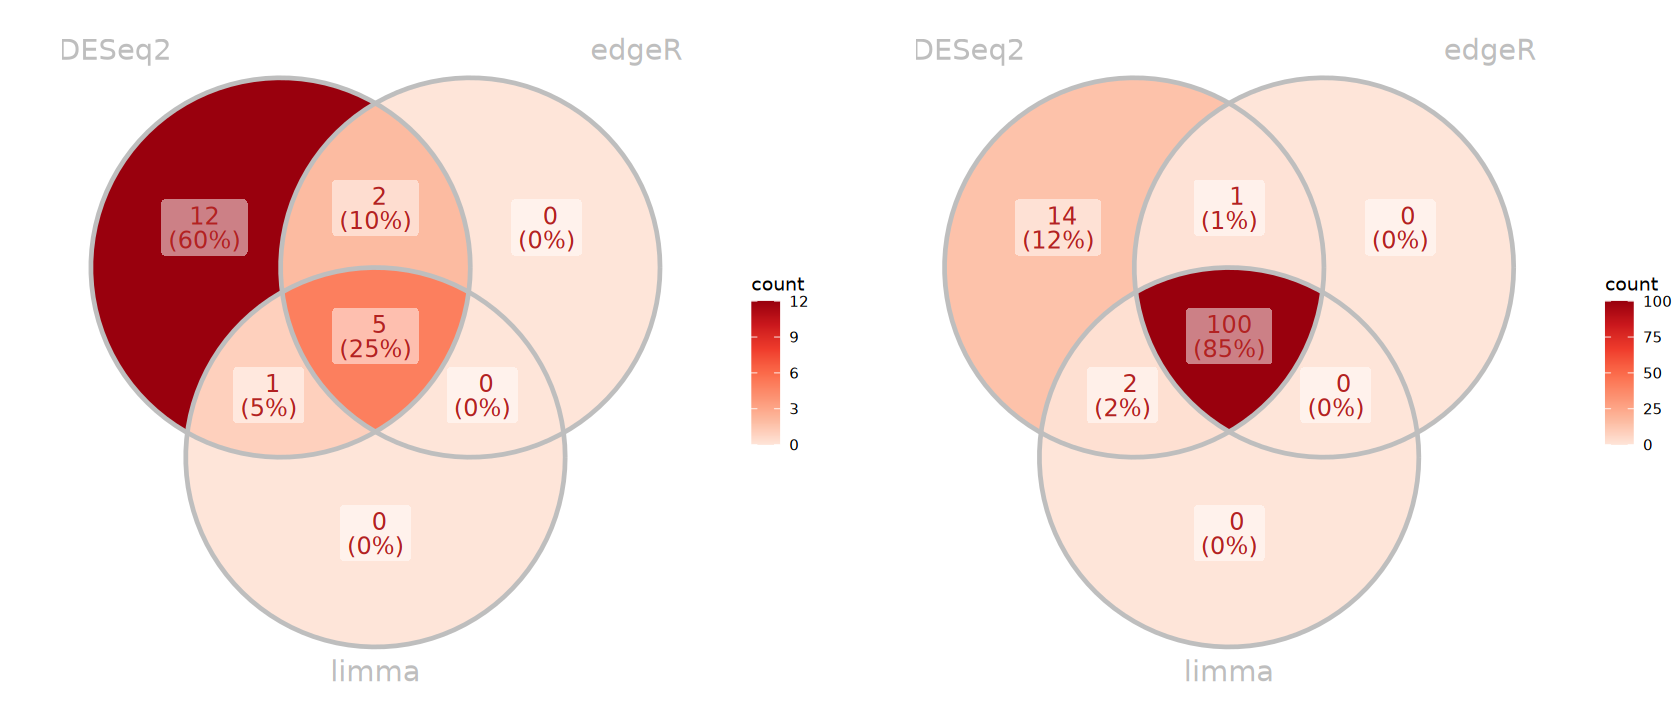

In [101]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Visualization

In [102]:
degs_result <- left_join(
    deseq2_result |> rownames_to_column("gene_id"), 
    te_matrix |> as.data.frame() |> rownames_to_column("gene_id"), 
    by = "gene_id") |>
    column_to_rownames("gene_id")

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_ctrl,te_treat
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>
ENSMUSG00000003660.10,3298.5742,0.5198569,0.13406947,4.586931e-06,0.0006735731,Up,Snrnp200,protein_coding,6408,TRUE,Snrnp200,-2.3360345,-1.5910250
ENSMUSG00000026615.14,2950.2943,0.5480898,0.14380367,6.902691e-06,0.0009412312,Up,Eprs,protein_coding,4536,TRUE,Eprs,-2.0140013,-1.2369450
ENSMUSG00000026553.17,4704.6957,0.3643298,0.09560322,6.850363e-06,0.0009412312,Up,Copa,protein_coding,3724,TRUE,Copa,-0.9918655,-0.4109124
ENSMUSG00000024740.10,7357.1760,0.4403817,0.12179028,9.592879e-06,0.0012567612,Up,Ddb1,protein_coding,3456,TRUE,Ddb1,-1.2166084,-0.5390927
ENSMUSG00000035049.4,725.9034,0.5224334,0.14229775,1.042599e-05,0.0013396394,Up,Rrp12,protein_coding,3885,TRUE,Rrp12,-1.4778859,-0.7162946
ENSMUSG00000024120.12,1468.0359,0.4573396,0.13007826,2.000068e-05,0.0025454194,Up,Lrpprc,protein_coding,4176,TRUE,NA,-1.3496204,-0.6532810


In [103]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(degs_result$te_ctrl) | is.infinite(degs_result$te_treat)
has_nan_or_na <- is.na(degs_result$te_ctrl) | is.na(degs_result$te_treat)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- degs_result[rows_with_abnormal, , drop = FALSE]

print(table(abnormal_data$result))

# 4. Output results to the console
if (nrow(abnormal_data[abnormal_data$result %in% c("Up", "Down"), ]) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(abnormal_data[
        abnormal_data$result %in% c("Up", "Down"), 
        c("logFC", "pvalue", "padj", "result", "symbol", "te_ctrl", "te_treat")])
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}


  Up Down   NS 
   0    0    2 
Success: No Inf, -Inf, NaN, or NA values detected in the table.


### Scatter Plot

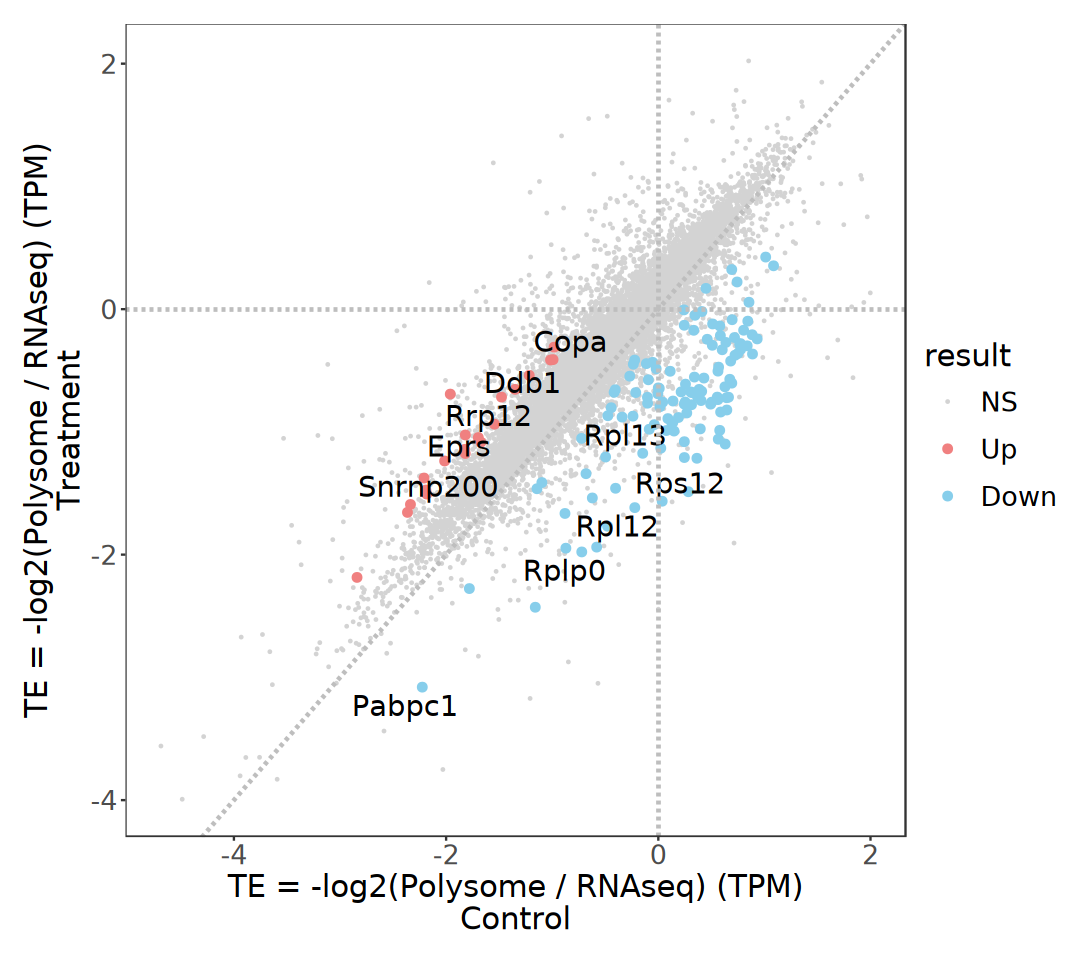

In [104]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$te_ctrl, degs_result$te_treat) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = te_ctrl, y = te_treat)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(x = "TE = -log2(Polysome / RNAseq) (TPM)\n Control ", 
         y = "TE = -log2(Polysome / RNAseq) (TPM)\n Treatment ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [105]:
design(dds)
resultsNames(dds)

~Group * Fraction

[1] "Intercept"                    "Group_Torin1_vs_DMSO"        
[3] "Fraction_Polysome_vs_Total"   "GroupTorin1.FractionPolysome"

In [106]:
# 1. Extract results from DESeq2
res_total <- results(dds, name = "Group_Torin1_vs_DMSO")
res_polysome <- results(dds, contrast = list(
    c("Group_Torin1_vs_DMSO", "GroupTorin1.FractionPolysome")))

In [107]:
# 2. Match and map log2FoldChange columns directly using row names
degs_result$log2FC_total  <- res_total[rownames(degs_result), "log2FoldChange"]
degs_result$log2FC_polysome <- res_polysome[rownames(degs_result), "log2FoldChange"]

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_ctrl,te_treat,log2FC_total,log2FC_polysome
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ENSMUSG00000003660.10,3298.5742,0.5198569,0.13406947,4.586931e-06,0.0006735731,Up,Snrnp200,protein_coding,6408,TRUE,Snrnp200,-2.3360345,-1.5910250,0.3139957,0.8939954
ENSMUSG00000026615.14,2950.2943,0.5480898,0.14380367,6.902691e-06,0.0009412312,Up,Eprs,protein_coding,4536,TRUE,Eprs,-2.0140013,-1.2369450,0.1730278,0.7818121
ENSMUSG00000026553.17,4704.6957,0.3643298,0.09560322,6.850363e-06,0.0009412312,Up,Copa,protein_coding,3724,TRUE,Copa,-0.9918655,-0.4109124,0.3375133,0.7445218
ENSMUSG00000024740.10,7357.1760,0.4403817,0.12179028,9.592879e-06,0.0012567612,Up,Ddb1,protein_coding,3456,TRUE,Ddb1,-1.2166084,-0.5390927,0.2371894,0.7429203
ENSMUSG00000035049.4,725.9034,0.5224334,0.14229775,1.042599e-05,0.0013396394,Up,Rrp12,protein_coding,3885,TRUE,Rrp12,-1.4778859,-0.7162946,-0.2227980,0.3655716
ENSMUSG00000024120.12,1468.0359,0.4573396,0.13007826,2.000068e-05,0.0025454194,Up,Lrpprc,protein_coding,4176,TRUE,NA,-1.3496204,-0.6532810,0.2907771,0.8092047


In [108]:
# colnames(design)

# # 1. Extract results from edgeR
# fit <- glmQLFit(dgel_nbglm, design)
# qlf <- glmQLFTest(fit, coef = "GroupTorin1")
# res_total <- topTags(qlf, n = Inf)$table

# qlf <- glmQLFTest(fit, contrast = c(0, 1, 0, 1))
# res_polysome <- topTags(qlf, n = Inf)$table

# # 2. Match and map log2FoldChange columns directly using row names
# degs_result$log2FC_total  <- res_total[rownames(degs_result), "logFC"]
# degs_result$log2FC_polysome <- res_polysome[rownames(degs_result), "logFC"]

# head(degs_result)

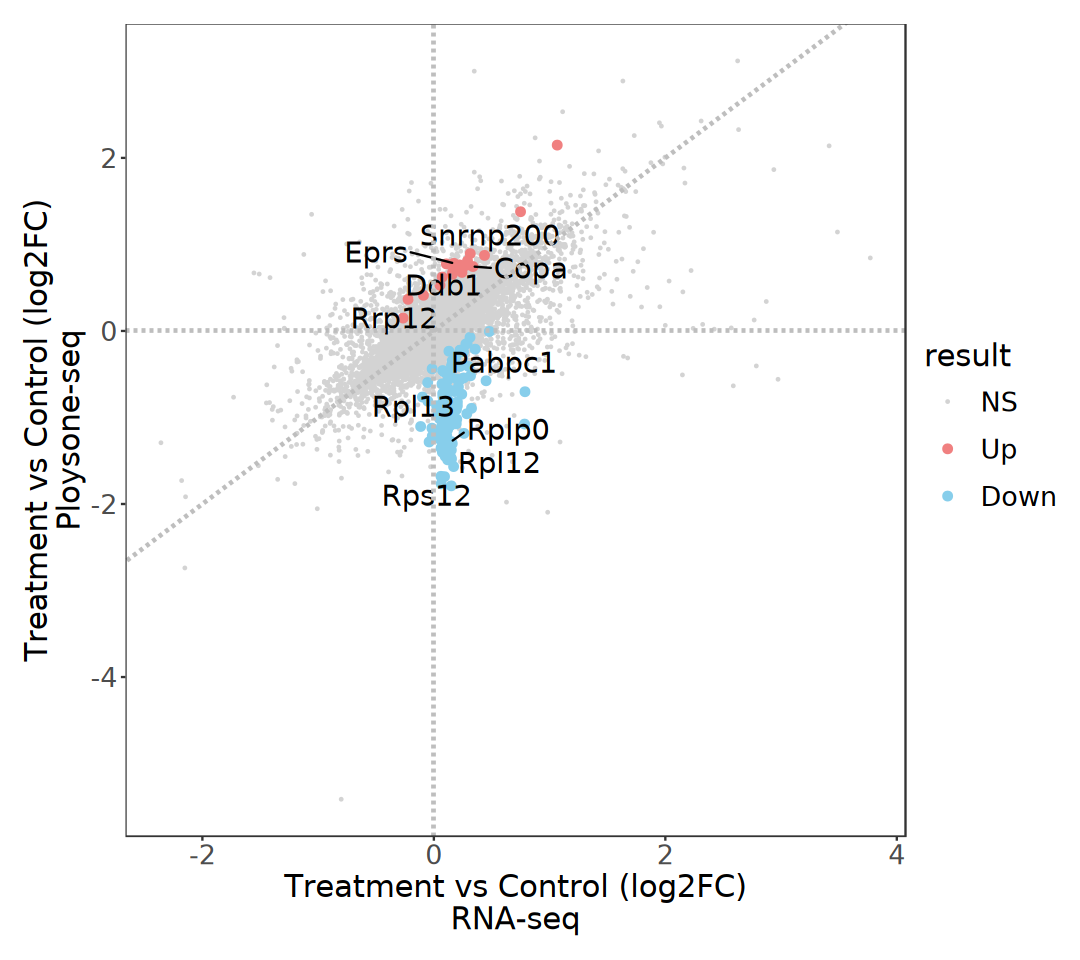

In [109]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$log2FC_total, degs_result$log2FC_polysome) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = log2FC_total, y = log2FC_polysome)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(
        x = "Treatment vs Control (log2FC)\n RNA-seq ", 
        y = "Treatment vs Control (log2FC)\n Ploysone-seq ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [110]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [111]:
ar <- degs_result |> 
    dplyr::select(DTEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [ ]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Fraction = fraction_colors, 
    Replicate = replicate_colors, DTEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

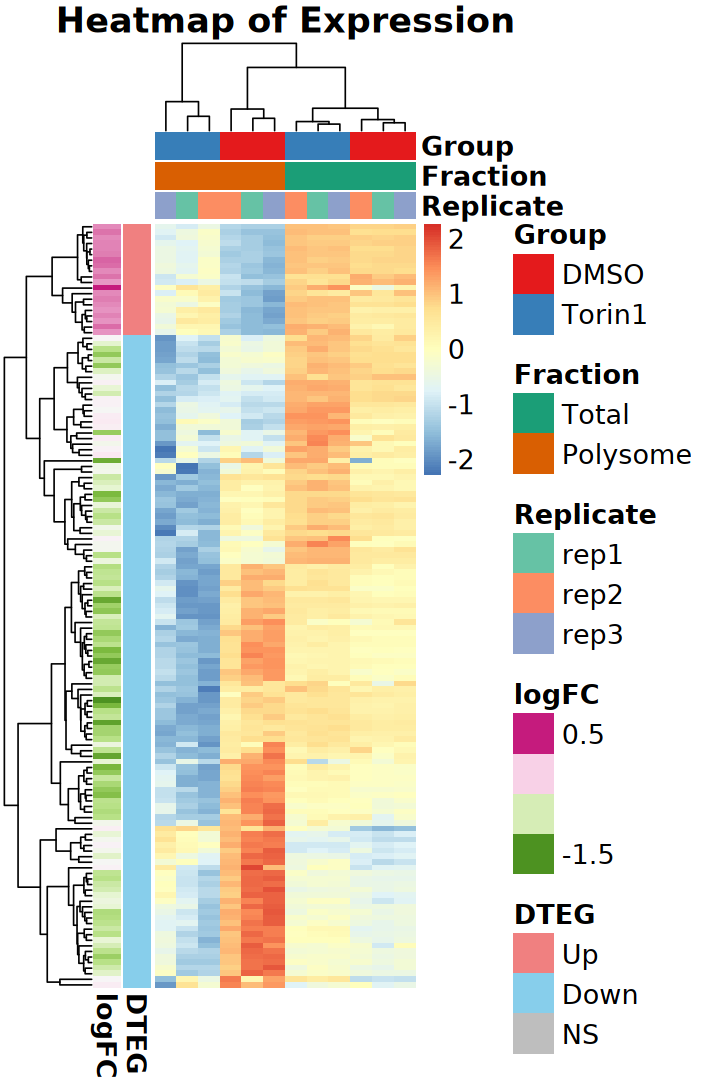

In [113]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [114]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [115]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [116]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [117]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Fraction, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Fraction = fraction_colors,
        Replicate = replicate_colors))

In [118]:
ar <- degs_result |> 
    dplyr::select(logFC, DTEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DTEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [119]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [120]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_fraction <- Legend(
    title = "Fraction", labels = levels(dds$Fraction))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DTEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_fraction, lg_replicate) |>
    packLegend(direction = "vertical")

In [121]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

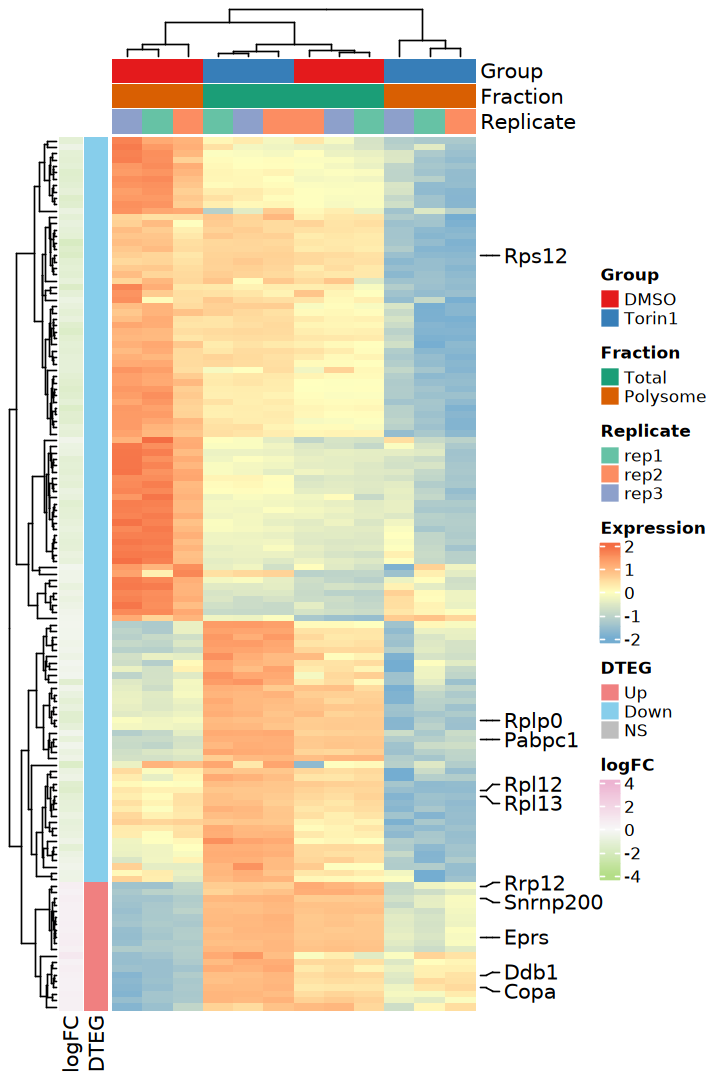

In [122]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

## 4). anota2seq

In [123]:
suppressPackageStartupMessages(library(anota2seq))

In [124]:
ads <- anota2seqDataSetFromMatrix(
    dataP = assay(eSet[, eSet$Fraction == "Polysome"], "counts"),
    dataT = assay(eSet[, eSet$Fraction == "Total"], "counts"),
    phenoVec = rep(c("DMSO", "Torin1"), each = 3),
    dataType = "RNAseq", normalize = TRUE)

ads

Removing zero count genes from data ...


51  genes were removed due to having 0 counts in at least one sample.


Count data will be normalized and transformed according to the TMM-log2 method.


All input checkpoints passed.




Information on input data.
dataP and dataT contain data for 13314 mRNA and 6 samples. 

Your sample classes are:
 	 DMSO Torin1 


No custom contrasts set, default will be used.
No differential expression analysis for translated mRNA has been detected.
No differential expression analysis for total mRNA has been detected.
No analysis of translation has been detected.
No analysis of buffering has been detected.
No selected data of differential expression analysis for translated mRNA has been detected.
No selected data of differential expression analysis for total mRNA has been detected.
No selected data of analysis of translation has been detected.
No selected data of analysis of buffering has been detected.

No output for mRNA abundance genes.

In [125]:
# ~ 3 min
ads <- anota2seqRun(ads)
ads

Running anota2seqPerformQc quality control


	Calculating omnibus interactions & effects and dfbetas




  |======================================================================| 100%





	Assessing dfbetas for model without interaction


	Performing dfbetas simulation




  |======================================================================| 100%





	Using RVM for omnibus interaction statistics


	The a and b parameters for the inverse gamma distribution are:
	a:1.37362411540642 b:28.8109249063862


	Using RVM for omnibus group statistics


	The a and b parameters for the inverse gamma distribution are:
	a:1.39602484766235 b:28.129596551779


	Adjusting p-values for multiple testing



Running anota2seqResidOutlierTest




  |======================================================================| 100%

... (10 outputs left out)

       contrast 1
DMSO           -1
Torin1          1


  |======================================================================| 100%





	Calculating RVM statistics


	Assessing contrast1


	The a and b parameters for the inverse gamma distribution are:
	a:0.715610002330757 b:181.297337985495


End of analysis of translational buffering.


Start filtering for significant genes ... 


Your filtering parameters are:


minSlopeTranslation:  -1 


maxSlopeTranslation:  2 


minSlopeBuffering:  -2 


maxSlopeBuffering:  1 


maxPAdj:  0.15 


maxP:   


minEff:   


deltaPT:  0.263034405833794 


deltaTP:  0.263034405833794 


deltaP:   


deltaT:   





Starting filtering of: translated mRNA


	filtering contrast 1.


	Contrast 1 done.


Filtering for analysis translated mRNA done.


Starting filtering of: total mRNA


	filtering contrast 1.


	Contrast 1 done.


Filtering for analysis total mRNA done.


Starting filtering of: translation


	filtering contrast 1.


Warning message in anota2seqSelSigGenes(Anota2seqDataSet, selContrast = c(1:dim(contrasts)[2]), :
"No genes pass selected thresholds for analysis of transla

Information on input data.
dataP and dataT contain data for 13314 mRNA and 6 samples. 

Your sample classes are:
 	 DMSO Torin1 

contrasts used in the analysis are:
			 Torin1 
	 DMSO 		 -1 	
	 Torin1 		 1 	


Output for differential expression analysis of translated mRNA detected.

Output for differential expression analysis of total mRNA detected.

Output for analysis of translation detected.

Output for analysis of buffering detected.

Output for differential expression analysis of translated mRNA detected:
Selected output of translated mRNA contains:
	for contrast 1 
		Total: 2628 genes.
		Positive log2FC: 1460 genes.
		Negative log2FC: 1168 genes.

Output for differential expression analysis of total mRNA detected:
Selected output of total mRNA contains:
	for contrast 1 
		Total: 5962 genes.
		Positive log2FC: 3014 genes.
		Negative log2FC: 2948 genes.

Output for analysis of translation detected:
Selected output of translation contains:
	for contrast 1 
		Total: 0 genes.
		Posit

Creating Fold-change plots.




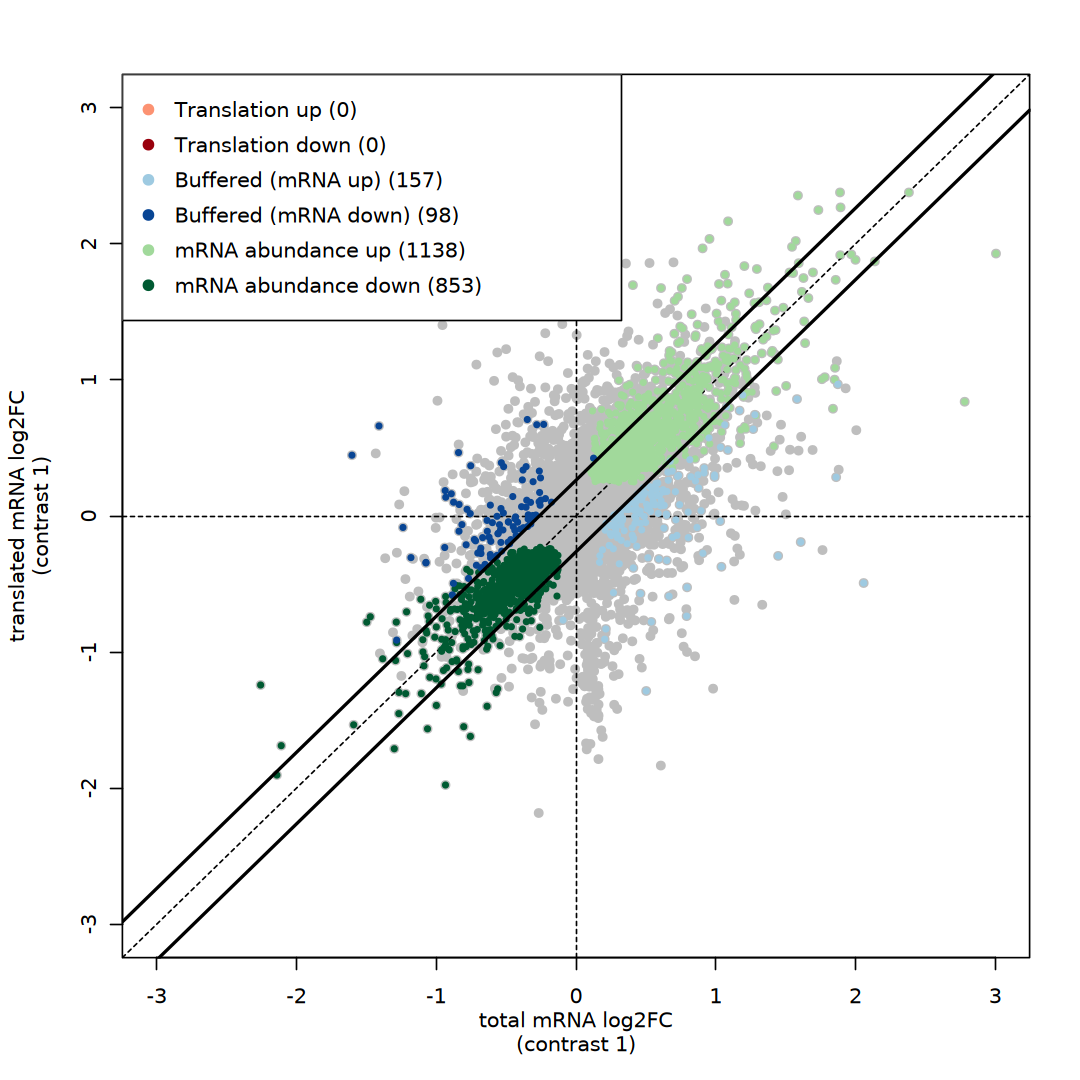

In [126]:
options(repr.plot.width = 9, repr.plot.height = 9)
anota2seqPlotFC(ads, selContrast = 1, plotToFile = FALSE)

In [127]:
ads_res <- anota2seqGetOutput(
    ads, analysis = "translation", output = "full", 
    getRVM = TRUE, selContrast = 1)

head(ads_res)

,apvSlope,apvSlopeP,apvEff,apvRvmMSerror,apvRvmF,residRvmDf,apvRvmP,apvRvmPAdj
ENSMUSG00000051951.5,0.7237771,1.0000000,0.50804401,0.08535432,3.02396785,5.005723,0.1424696,0.6565346
ENSMUSG00000025902.13,0.8998798,1.0000000,-0.36393542,0.28886653,0.45851276,5.005723,0.5283438,0.8880659
ENSMUSG00000033845.13,-1.9467197,0.3945454,-0.22966948,0.13922134,0.37887920,5.005723,0.5651091,0.9012442
ENSMUSG00000025903.14,1.4764524,0.3691035,-0.03273161,0.07674903,0.01395924,5.005723,0.9105440,0.9872390
ENSMUSG00000033813.15,4.5933216,0.3205242,-0.63036670,0.82056828,0.48425242,5.005723,0.5174804,0.8822812
ENSMUSG00000002459.17,-0.3177507,0.3430035,0.28532409,0.04616270,1.76354146,5.005723,0.2415128,0.7388602


# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)